In [44]:
### Debugging Lissajous scan implementaion on new Toast version release 3

In [45]:
import toast
import toast.io as io
import toast.ops

import numpy as np
import os

import astropy.units as u
import matplotlib.pyplot as plt

In [46]:
comm, procs, rank = toast.get_world()

# toast_comm = toast.Comm(world=comm, groupsize=1)
toast_comm = toast.Comm(world=comm)

# Create the (empty) data
data = toast.Data(comm=toast_comm)

# sim_ground = toast.ops.SimGround()

In [47]:
print(f"Using TOAST version: {toast.__version__}")

Using TOAST version: 3.0.2


### Loading h5 Obs files
In this format, we have as many total obs, as there are scans in the scedule file. So each row in the schedule file produces one h5 file, which corresponds to one obs.

In [48]:
# obs_dir_h5 = "../ccat_datacenter_mock/mockdata_test1/orionA_NOATMdata_d100/sim_PCAM280_h5_ORIONA_2026_07_15_d100/"
obs_dir_h5 = "../ccat_datacenter_mock/mockdata_test1/orionA_ATMdata_d100/sim_PCAM280_h5_ORIONA_2026_07_15_d100/"
# obs_dir_h5 = "../ccat_datacenter_mock/data_testmpi/orionA_ATMdata_d100/sim_PCAM280_h5_ORIONA_2026_07_15_d100/"

In [49]:
## Loads 1 h5 dir and h5 files in the obs_dir_h5
limit_obs = False
h5dir_path=obs_dir_h5
if os.path.isdir(h5dir_path):
    print("\n")
    print(f"Loading h5 dir: {h5dir_path} ...")

for h5file in os.listdir(h5dir_path):
    print(h5file)
    h5file_path = os.path.join(h5dir_path, h5file)
    print(f"Loading h5 file: {h5file} ...")

    if os.path.isfile(h5file_path) and h5file.endswith(".h5"):
        # Load the observation from the HDF5 file
        obs = io.load_hdf5(path=h5file_path, comm=toast_comm)
        # Append the observation
        data.obs.append(obs)
        if limit_obs and len(data.obs) >= 3:
            break

print(f"Number of Observations Loaded: {len(data.obs)}")



Loading h5 dir: ../ccat_datacenter_mock/mockdata_test1/orionA_ATMdata_d100/sim_PCAM280_h5_ORIONA_2026_07_15_d100/ ...
ORIONA_2026_07_15-3-0.h5
Loading h5 file: ORIONA_2026_07_15-3-0.h5 ...
ORIONA_2026_07_15-4-0.h5
Loading h5 file: ORIONA_2026_07_15-4-0.h5 ...
ORIONA_2026_07_15-2-0.h5
Loading h5 file: ORIONA_2026_07_15-2-0.h5 ...
ORIONA_2026_07_15-6-0.h5
Loading h5 file: ORIONA_2026_07_15-6-0.h5 ...
ORIONA_2026_07_15-7-0.h5
Loading h5 file: ORIONA_2026_07_15-7-0.h5 ...
ORIONA_2026_07_15-0-0.h5
Loading h5 file: ORIONA_2026_07_15-0-0.h5 ...
ORIONA_2026_07_15-1-0.h5
Loading h5 file: ORIONA_2026_07_15-1-0.h5 ...
ORIONA_2026_07_15-5-0.h5
Loading h5 file: ORIONA_2026_07_15-5-0.h5 ...
Number of Observations Loaded: 8


In [50]:
obs0 = data.obs[0]
obs0

<Observation
  name = 'ORIONA_2026_07_15-3-0'
  uid = '3480667865'  group has 1 processes
  telescope = <Telescope 'FYST': uid = 1388067617, site = <GroundSite 'Cerro-Chajnantor' : uid = 3975474032, lon = -67.74000000000001 deg, lat = -22.986 deg, alt = 5610.00000000199 m, weather = <SimWeather : 'atacama', year = 2026, month = 6, hour = 11, site UID = 3975474032, realization = 0, median = False)>, focalplane = <Focalplane: 100 detectors, sample_rate = 488.0 Hz, FOV = 1.4586000000000001 deg, detectors = [w2_p0000_PC_f280_A .. w2_p1727_PC_f280_B]>>
  session = <Session 'ORIONA_2026_07_15-3-0': uid = 2599943713, start = 2026-07-15 11:35:00+00:00, end = 2026-07-15 11:40:00+00:00>
  el_noise_model = <Noise model with 100 detectors each built from between 1 and 1 independent streams>
  noise_model = <AnalyticNoise model with 100 detectors>
  scan_el = 43.99 deg
  scan_max_az = 1.3507975745810115 rad
  scan_max_el = 0.785223630472249 rad
  scan_min_az = 1.2809844045012382 rad
  scan_min_el =

### Az-El Pointing Plots

In [51]:
det_pointing_radec = toast.ops.PointingDetectorSimple(name="det_pointing_radec", 
                                                      boresight="boresight_radec",
                                                      quats="quats_radec")
det_pointing_radec.exec(data)

In [52]:
det_pointing_azel = toast.ops.PointingDetectorSimple(
                                                    name="det_pointing_azel",            
                                                    boresight="boresight_azel",
                                                    quats="quats_azel"
                                                )
det_pointing_azel.exec(data)

In [53]:

obs0 = data.obs[0]
obs0

<Observation
  name = 'ORIONA_2026_07_15-3-0'
  uid = '3480667865'  group has 1 processes
  telescope = <Telescope 'FYST': uid = 1388067617, site = <GroundSite 'Cerro-Chajnantor' : uid = 3975474032, lon = -67.74000000000001 deg, lat = -22.986 deg, alt = 5610.00000000199 m, weather = <SimWeather : 'atacama', year = 2026, month = 6, hour = 11, site UID = 3975474032, realization = 0, median = False)>, focalplane = <Focalplane: 100 detectors, sample_rate = 488.0 Hz, FOV = 1.4586000000000001 deg, detectors = [w2_p0000_PC_f280_A .. w2_p1727_PC_f280_B]>>
  session = <Session 'ORIONA_2026_07_15-3-0': uid = 2599943713, start = 2026-07-15 11:35:00+00:00, end = 2026-07-15 11:40:00+00:00>
  el_noise_model = <Noise model with 100 detectors each built from between 1 and 1 independent streams>
  noise_model = <AnalyticNoise model with 100 detectors>
  scan_el = 43.99 deg
  scan_max_az = 1.3507975745810115 rad
  scan_max_el = 0.785223630472249 rad
  scan_min_az = 1.2809844045012382 rad
  scan_min_el =

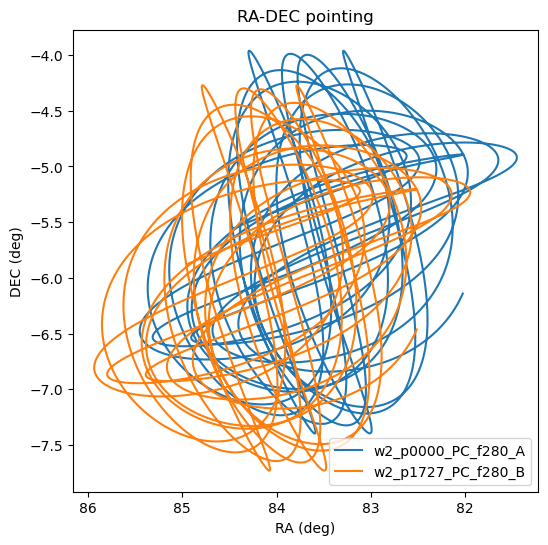

In [54]:
from toast.qarray import to_iso_angles

det1_radec_quat = obs0.detdata['quats_radec']['w2_p0000_PC_f280_A']
theta, phi, psi =  to_iso_angles(det1_radec_quat)
det1_ra = np.degrees(phi)
det1_dec = 90 - np.degrees(theta)

det2_radec_quat = obs0.detdata['quats_radec']['w2_p1727_PC_f280_B']
theta, phi, psi =  to_iso_angles(det2_radec_quat)
det2_ra = np.degrees(phi)
det2_dec = 90 - np.degrees(theta)


fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111)

plt.plot(det1_ra, det1_dec, label='w2_p0000_PC_f280_A')
plt.plot(det2_ra, det2_dec, label='w2_p1727_PC_f280_B')
ax.invert_xaxis()
plt.ylabel('DEC (deg)')
plt.xlabel('RA (deg)')
plt.title('RA-DEC pointing')
plt.legend()
plt.show()

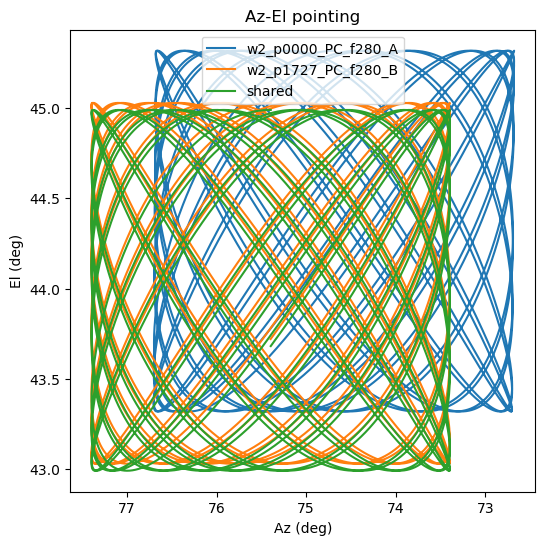

In [55]:
from toast.qarray import to_lonlat_angles

det1_azel_quat = obs0.detdata['quats_azel']['w2_p0000_PC_f280_A']
lon, lat, psi =  to_lonlat_angles(det1_azel_quat)
det1_az = -np.degrees(lon)
det1_el = np.degrees(lat)

det2_azel_quat = obs0.detdata['quats_azel']['w2_p1727_PC_f280_B']
lon, lat, psi =  to_lonlat_angles(det2_azel_quat)
det2_az = -np.degrees(lon)
det2_el = np.degrees(lat)

az_obs_shared = obs0.shared["azimuth"]
el_obs_shared = obs0.shared["elevation"]

fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111)

plt.plot(det1_az, det1_el, label='w2_p0000_PC_f280_A')
plt.plot(det2_az, det2_el, label='w2_p1727_PC_f280_B')
plt.plot(np.degrees(az_obs_shared), np.degrees(el_obs_shared), label='shared')
ax.invert_xaxis()
plt.ylabel('El (deg)')
plt.xlabel('Az (deg)')
plt.title('Az-El pointing')
plt.legend()
plt.show()

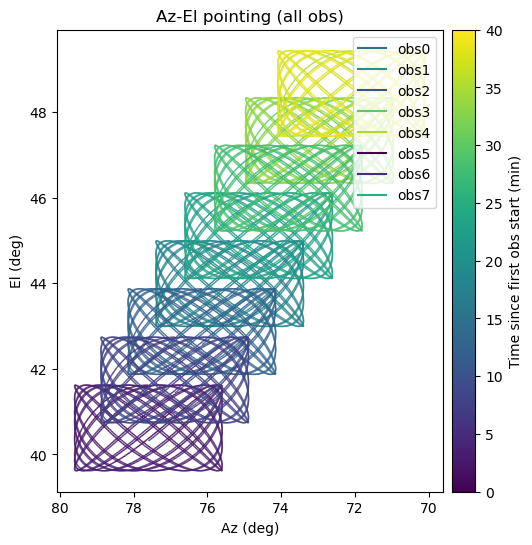

In [56]:

from toast.qarray import to_lonlat_angles
import datetime as _dt
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize

fig = plt.figure(figsize=(6, 6))
ax = plt.subplot(111)
def _as_datetime(x):
    if isinstance(x, _dt.datetime):
        return x
    if hasattr(x, "to_datetime"):
        return x.to_datetime()
    if hasattr(x, "datetime"):
        return x.datetime
    # last resort
    return _dt.datetime.fromisoformat(str(x).replace("Z", "+00:00"))

_fs_hz = 488.0  # sample rate

# Global time range (minutes) from first obs start to last obs end
_first_start = min(_as_datetime(o.session.start) for o in data.obs)
_last_end = max(_as_datetime(o.session.end) for o in data.obs)
_tmax_min = (_last_end - _first_start).total_seconds() / 60.0

# Per-obs start offsets (minutes since first_start)
_obs_start_min = [
    (_as_datetime(o.session.start) - _first_start).total_seconds() / 60.0 for o in data.obs
]

_cmap = plt.get_cmap("viridis")
_norm = Normalize(vmin=0.0, vmax=_tmax_min)

# Colorbar (time in minutes since first obs start)
_sm = plt.cm.ScalarMappable(norm=_norm, cmap=_cmap)
_sm.set_array([])
_cbar = fig.colorbar(_sm, ax=ax, pad=0.02)
_cbar.set_label("Time since first obs start (min)")

# Monkeypatch plt.plot so the existing loop draws time-colored line segments
_orig_plot = plt.plot
_orig_show = plt.show
_plot_obs_idx = 0

def _plot_timecolored(x, y, *args, label=None, **kwargs):
    global _plot_obs_idx
    idx = _plot_obs_idx
    _plot_obs_idx += 1

    x = np.asarray(x)
    y = np.asarray(y)
    n = x.size
    if n < 2:
        return _orig_plot(x, y, *args, label=label, **kwargs)

    # Downsample for speed while keeping the time span correct
    target_pts = 8000
    step = max(1, n // target_pts)
    xds = x[::step]
    yds = y[::step]

    t0 = _obs_start_min[idx]
    tmin = t0 + (np.arange(xds.size) * step) / _fs_hz / 60.0  # minutes

    pts = np.column_stack([xds, yds]).reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)

    lc = LineCollection(segs, cmap=_cmap, norm=_norm)
    lc.set_array(tmin[:-1])
    lc.set_linewidth(1.0)
    ax.add_collection(lc)

    # Proxy artist for legend entry
    proxy_color = _cmap(_norm(t0))
    (proxy,) = ax.plot([], [], color=proxy_color, label=label)
    return [proxy]

def _restore_and_show(*args, **kwargs):
    try:
        return _orig_show(*args, **kwargs)
    finally:
        plt.plot = _orig_plot
        plt.show = _orig_show

plt.plot = _plot_timecolored
plt.show = _restore_and_show
for i, obs in enumerate(data.obs):
    az_obs_shared = obs.shared["azimuth"]
    el_obs_shared = obs.shared["elevation"]
    plt.plot(np.degrees(az_obs_shared), np.degrees(el_obs_shared), label=f"obs{i}")

ax.invert_xaxis()
plt.ylabel("El (deg)")
plt.xlabel("Az (deg)")
plt.title("Az-El pointing (all obs)")
plt.legend()
plt.show()


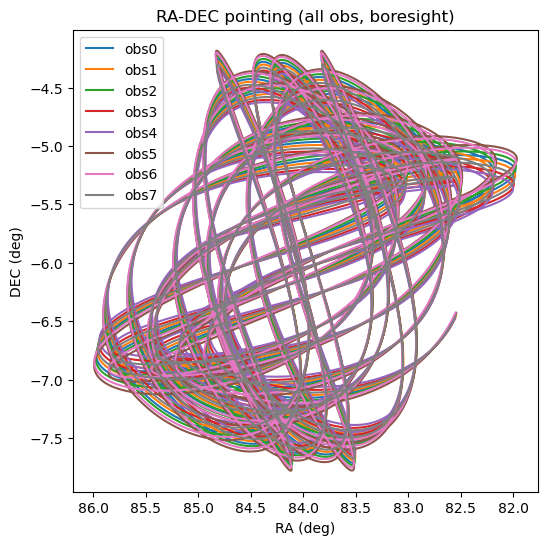

In [57]:
from toast.qarray import to_iso_angles

fig = plt.figure(figsize=(6, 6))
ax = plt.subplot(111)

for i, obs in enumerate(data.obs):
    # Use boresight (shared) RA/DEC quaternions
    bore_quat = obs.shared["boresight_radec"]

    theta, phi, psi = to_iso_angles(bore_quat)

    # Unwrap RA for continuous lines, then convert to degrees
    ra = np.degrees(np.unwrap(phi))
    dec = 90.0 - np.degrees(theta)

    ax.plot(ra, dec, label=f"obs{i}")

ax.invert_xaxis()
plt.ylabel("DEC (deg)")
plt.xlabel("RA (deg)")
plt.title("RA-DEC pointing (all obs, boresight)")
plt.legend()
plt.show()


In [58]:
obs0.detdata

<DetDataManager 100 local detectors, 146401 samples
    flags: shape=(100, np.int64(146401)), dtype=uint8, units=''
    signal: shape=(100, np.int64(146401)), dtype=float64, units='K'
    quats_radec: shape=(100, np.int64(146401), 4), dtype=float64, units=''
    quats_azel: shape=(100, np.int64(146401), 4), dtype=float64, units=''>

In [59]:
flags = np.asarray(obs0.shared["flags"])
nz = np.flatnonzero(flags)

print(f"Total samples: {flags.size}")
print(f"Non-zero samples: {nz.size}")

if nz.size:
    # Show which flag values occur and how many times
    vals, counts = np.unique(flags[nz], return_counts=True)
    print("Non-zero flag value counts:")
    for v, c in zip(vals.tolist(), counts.tolist()):
        print(f"  {int(v)}: {c}")

    # Print some example indices / values
    print("\nFirst 100 non-zero samples (idx, val):")
    for j in nz[:100]:
        print(j, int(flags[j]))

Total samples: 146401
Non-zero samples: 0


### TOD Plots

In [60]:
data.obs[0].all_detectors[::10]

[np.str_('w2_p0000_PC_f280_A'),
 np.str_('w2_p0176_PC_f280_A'),
 np.str_('w2_p0352_PC_f280_A'),
 np.str_('w2_p0529_PC_f280_A'),
 np.str_('w2_p0704_PC_f280_A'),
 np.str_('w2_p0881_PC_f280_A'),
 np.str_('w2_p1058_PC_f280_A'),
 np.str_('w2_p1233_PC_f280_A'),
 np.str_('w2_p1409_PC_f280_A'),
 np.str_('w2_p1585_PC_f280_A')]

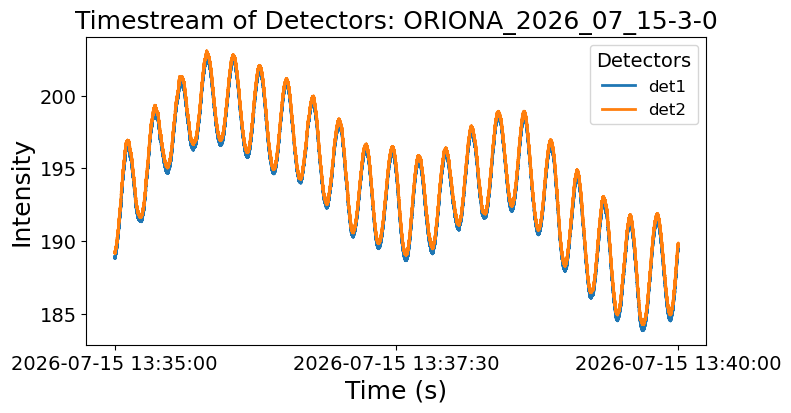

In [61]:
import datetime
def func_time_hms(times):
    #plotting 5 time tick-labels
    idx_t = np.round(np.linspace(0, len(times) - 1, 3)).astype(int)
    times_hms = [datetime.datetime.fromtimestamp(timestamps).strftime("%Y-%m-%d %H:%M:%S") 
              for timestamps in times[idx_t]]
    # times_hms = [datetime.datetime.fromtimestamp(timestamps).strftime("%H:%M:%S") 
    #       for timestamps in times[idx_t]]
    
    return(idx_t, times_hms)

obs0 = data.obs[0]
t0 = obs0.shared["times"] # Observation 9
tod0_0 = obs0.detdata["signal"][0]
tod0_1 = obs0.detdata["signal"][50]
shared_times = obs0.shared["times"]

fig = plt.figure(figsize=(8, 4))
ax_1 = fig.add_subplot(1, 1, 1)

# Plot each time series data
ax_1.plot(shared_times, tod0_0, label='det1', linewidth=2)
ax_1.plot(shared_times, tod0_1, label='det2', linewidth=2)

idx_1, times1_hms = func_time_hms(shared_times)
ax_1.set_xticks(shared_times[idx_1])
ax_1.set_xticklabels(times1_hms, fontsize = 14)
ax_1.tick_params(axis='y', which='major', labelsize=14)

plt.legend(title='Detectors', fontsize=12, title_fontsize=14)

plt.xlabel('Time (s)', fontsize=18)
plt.ylabel("Intensity", fontsize=18)

plt.title(f'Timestream of Detectors: {obs0.session.name}', fontsize=18)
# plt.savefig("tod_cesv3_deep56_10d.png")
plt.show()

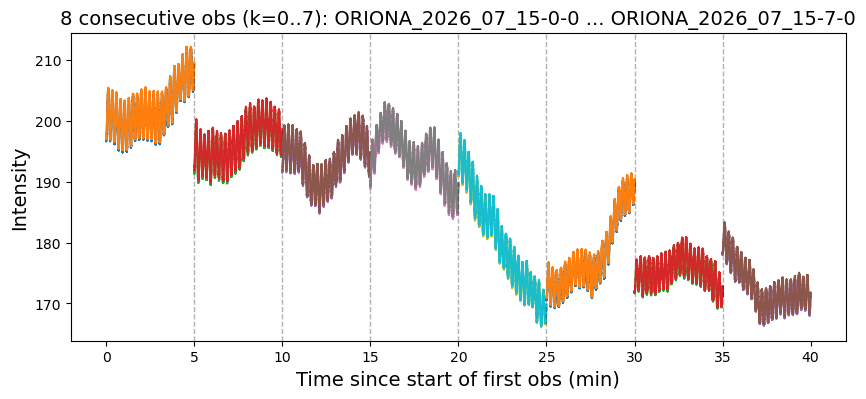

In [62]:
# Pick n consecutive observations in time order (default n=4)
obs_sorted = sorted(data.obs, key=lambda o: _as_datetime(o.session.start))

n = 9  # number of consecutive obs to plot
k = 0  # starting index in time-sorted list

if len(obs_sorted) == 0:
    raise RuntimeError("No observations found in data.obs")

if k < 0 or k >= len(obs_sorted):
    raise IndexError(f"k={k} out of range for {len(obs_sorted)} observations")

n = max(1, int(n))
n = min(n, len(obs_sorted) - k)

obs_seq = obs_sorted[k : k + n]

# Same two detector indices as before
det_idx0, det_idx1 = 0, 50

# Time in minutes, starting at 0 from the first sample of the first obs in the sequence
t_ref = float(np.asarray(obs_seq[0].shared["times"])[0])

# Optional downsample for plotting speed
target_pts = 20000
def _ds(t, y):
    step = max(1, len(t) // target_pts)
    return t[::step], y[::step]

fig = plt.figure(figsize=(10, 4))
ax_1 = fig.add_subplot(1, 1, 1)

for j, obs in enumerate(obs_seq):
    t = (np.asarray(obs.shared["times"]) - t_ref) / 60.0

    s0 = np.asarray(obs.detdata["signal"][det_idx0])
    s1 = np.asarray(obs.detdata["signal"][det_idx1])

    t0d, s0d = _ds(t, s0)
    t1d, s1d = _ds(t, s1)

    ax_1.plot(t0d, s0d, lw=1.5, label=f"{obs.session.name} det[{det_idx0}]")
    ax_1.plot(t1d, s1d, lw=1.5, label=f"{obs.session.name} det[{det_idx1}]")

    # Mark obs boundary (end time) except for the last one
    if j < len(obs_seq) - 1:
        t_end = (float(np.asarray(obs.shared["times"])[-1]) - t_ref) / 60.0
        ax_1.axvline(t_end, color="k", ls="--", lw=1.0, alpha=0.3)

ax_1.set_xlabel("Time since start of first obs (min)", fontsize=14)
ax_1.set_ylabel("Intensity", fontsize=14)
ax_1.set_title(
    f"{n} consecutive obs (k={k}..{k+n-1}): {obs_seq[0].session.name} ... {obs_seq[-1].session.name}",
    fontsize=14,
)
# ax_1.grid(True, alpha=0.3)
# ax_1.legend(fontsize=9, ncols=2)

plt.show()